# Clase 4 — Aprender sin mapa: Monte Carlo, TD, SARSA y Q-learning

**RL a ciegas · vía profunda** — basado en CS234 (Brunskill), clases de *model-free policy evaluation* y *model-free control*, y Sutton & Barto cap. 5–6.

En la clase 3 el agente tenía el mapa: conocía $P$ y $R$ y podía calcular $V^*$ con Bellman. En el juego eso no pasa: **la cueva está a oscuras**. El agente solo sabe dónde está, qué hizo, qué recompensa recibió y adónde fue a parar. Hoy aprendemos **solo con esa experiencia** (*model-free*).

Hoy vamos a ver:

1. Qué información tiene el agente sin mapa.
2. **Monte Carlo** (MC): evaluar una política promediando retornos de partidas completas.
3. **Diferencia temporal** (*temporal difference*, TD(0)): aprender paso a paso, sin esperar al final.
4. MC vs TD contra la $V$ verdadera de la clase 3.
5. **SARSA** y **Q-learning**: aprender a *actuar* bien, con exploración $\varepsilon$-greedy.
6. Lo aprendido vs lo óptimo, y el **mapa de visitas**.

### Preparación

La primera celda escribe el entorno `cave_env.py`; la segunda importa lo necesario.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 3 (con modelo): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax


Overwriting cave_env.py


In [2]:
from cave_env import CaveEnv, ACTION_NAMES
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
plt.rcParams["figure.dpi"] = 100

### Herramientas

Funciones de la clase: las de la clase 3 (para tener la respuesta correcta y comparar), Monte Carlo, TD(0), SARSA, Q-learning y dibujos. **No hace falta leerla**: está plegada. `plot_cave` es el mismo `env.plot` de siempre, con las flechas remarcadas.

In [3]:
# @title Herramientas (plegada)
# Herramientas: no hace falta leer esto
import matplotlib.patheffects as pe

# ---------- dibujo ----------
def plot_cave(env, values=None, policy=None, path=None, ax=None, title=None,
              cmap="magma", clim=None, show_walls=True):
    """env.plot con flechas con borde y escala de color calculada sin la salida."""
    ax = env.plot(values=values, policy=policy, path=path, ax=ax, title=title,
                  cmap=cmap, show_walls=show_walls)
    if values is not None:
        if clim is None:
            v = np.asarray(values, dtype=float)[np.arange(env.nS) != env.goal]
            clim = (np.nanmin(v), np.nanmax(v))
        lo, hi = clim
        if hi - lo < 1e-12:
            lo = hi - 1.0
        ax.images[-1].set_clim(lo, hi)
    for t in ax.texts:
        t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="black")])
    return ax


def plot_row(env, values_list, titles, policies=None, paths=None, shared=True,
             cmap="magma", size=4.3):
    n = len(values_list)
    fig, axes = plt.subplots(1, n, figsize=(size * n, size * env.H / env.W + 0.6))
    axes = np.atleast_1d(axes)
    notgoal = np.arange(env.nS) != env.goal
    clim = (min(np.min(v[notgoal]) for v in values_list), max(np.max(v[notgoal]) for v in values_list))
    for i, ax in enumerate(axes):
        plot_cave(env, values=values_list[i], ax=ax, title=titles[i], cmap=cmap,
                  policy=None if policies is None else policies[i],
                  path=None if paths is None else paths[i],
                  clim=clim if shared else None)
    plt.tight_layout(); plt.show()


def plot_agent_view(env, path, ax, title):
    """Lo que 've' el agente: solo las paredes que tocó (gris claro) y su recorrido."""
    env.plot(ax=ax, show_walls=False, path=path, title=title)
    for (r, c) in env.touched:
        ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color=(0.8, 0.8, 0.8)))


def smooth(x, w=20):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(w) / w, mode="valid")


# ---------- clase 3 (con modelo): la respuesta correcta ----------
def policy_evaluation(env, pi, gamma, tol=1e-10):
    V = np.zeros(env.nS)
    while True:
        V_new = (pi * (env.R + gamma * env.P @ V)).sum(axis=1)
        if np.max(np.abs(V_new - V)) < tol:
            return V_new
        V = V_new


def value_iteration(env, gamma, tol=1e-10):
    V = np.zeros(env.nS)
    while True:
        Q = env.R + gamma * env.P @ V
        V_new = Q.max(axis=1)
        if np.max(np.abs(V_new - V)) < tol:
            Q = env.R + gamma * env.P @ V_new
            return V_new, Q.argmax(axis=1), Q
        V = V_new


# ---------- jugar ----------
def reset_random(env, rng):
    """Aparecer en una casilla al azar (que no sea la salida)."""
    env.reset()
    env.s = int(rng.choice([s for s in range(env.nS) if s != env.goal]))
    return env.s


def play_random_episode(env, rng, random_start=True):
    """Una partida con la política aleatoria. Devuelve la lista de (s, r, s')."""
    s = reset_random(env, rng) if random_start else env.reset()
    traj = []
    while True:
        a = int(rng.integers(env.nA))
        s2, r, done, info = env.step(a)
        traj.append((s, r, s2, info["reached_goal"]))
        s = s2
        if done:
            return traj


# ---------- evaluación sin modelo ----------
def mc_update(V, N, traj, gamma):
    """Monte Carlo first-visit: promedio de los retornos desde la primera visita a cada casilla."""
    G, first_return = 0.0, {}
    for s, r, s2, _ in reversed(traj):
        G = r + gamma * G
        first_return[s] = G              # al ir hacia atrás, queda el de la PRIMERA visita
    for s, G in first_return.items():
        N[s] += 1
        V[s] += (G - V[s]) / N[s]


def td_update(V, traj, gamma, alpha):
    """TD(0): después de cada paso, mover V(s) hacia r + gamma V(s')."""
    for s, r, s2, terminal in traj:
        target = r + (0.0 if terminal else gamma * V[s2])
        V[s] += alpha * (target - V[s])


def compare_mc_td(env, V_true, gamma, n_episodes=400, alpha=0.05, seeds=range(5)):
    """MC y TD ven exactamente las mismas partidas. Devuelve errores (seeds x episodios) y la última V."""
    notgoal = np.arange(env.nS) != env.goal
    rmse = lambda V: np.sqrt(np.mean((V[notgoal] - V_true[notgoal]) ** 2))
    err_mc, err_td = [], []
    for seed in seeds:
        rng = np.random.default_rng(seed)
        V_mc, N, V_td = np.zeros(env.nS), np.zeros(env.nS), np.zeros(env.nS)
        e_mc, e_td = [], []
        for ep in range(n_episodes):
            traj = play_random_episode(env, rng)
            mc_update(V_mc, N, traj, gamma)
            td_update(V_td, traj, gamma, alpha)
            e_mc.append(rmse(V_mc)); e_td.append(rmse(V_td))
        err_mc.append(e_mc); err_td.append(e_td)
    return np.array(err_mc), np.array(err_td), V_mc, V_td


# ---------- control sin modelo ----------
def learn(env, method="qlearning", n_episodes=500, alpha=0.5, epsilon=0.1, gamma=0.99, seed=0):
    """SARSA o Q-learning tabular con política epsilon-greedy. Q arranca en 0."""
    rng = np.random.default_rng(seed)
    env.rng = np.random.default_rng(seed)
    Q = np.zeros((env.nS, env.nA))
    visits = np.zeros((n_episodes, env.nS))
    steps, success = [], []

    def act(s):
        if rng.random() < epsilon:
            return int(rng.integers(env.nA))                  # explorar
        best = np.flatnonzero(Q[s] == Q[s].max())
        return int(rng.choice(best))                          # explotar (empates al azar)

    for ep in range(n_episodes):
        s = env.reset(); a = act(s); visits[ep, s] += 1
        while True:
            s2, r, done, info = env.step(a)
            visits[ep, s2] += 1
            a2 = act(s2)
            if info["reached_goal"]:
                target = r
            elif method == "sarsa":
                target = r + gamma * Q[s2, a2]                # la acción que voy a hacer
            else:
                target = r + gamma * Q[s2].max()              # la mejor acción posible
            Q[s, a] += alpha * (target - Q[s, a])
            s, a = s2, a2
            if done:
                break
        steps.append(env.t); success.append(info["reached_goal"])
    return dict(Q=Q, steps=np.array(steps), success=np.array(success), visits=visits)


def run_policy(env, policy, max_steps=100, seed=0):
    env.rng = np.random.default_rng(seed)
    s = env.reset(); path = [s]
    for _ in range(max_steps):
        s, r, done, info = env.step(int(policy[s])); path.append(s)
        if info["reached_goal"]:
            break
    return path


def frac_optimal(env, policy, Q_star, states=None):
    """Fracción de casillas donde la acción elegida es óptima (según Q* de value iteration)."""
    opt = np.isclose(Q_star, Q_star.max(axis=1, keepdims=True), atol=1e-6)
    states = [s for s in range(env.nS) if s != env.goal] if states is None else states
    return np.mean([opt[s, policy[s]] for s in states])

## Paso 1 — Sin mapa: ¿qué sabe el agente?

Hagamos jugar al agente 200 pasos al azar y comparemos **lo que ve él** (solo las paredes que tocó, como en el juego) con **lo que sabemos nosotros** (el mapa completo).

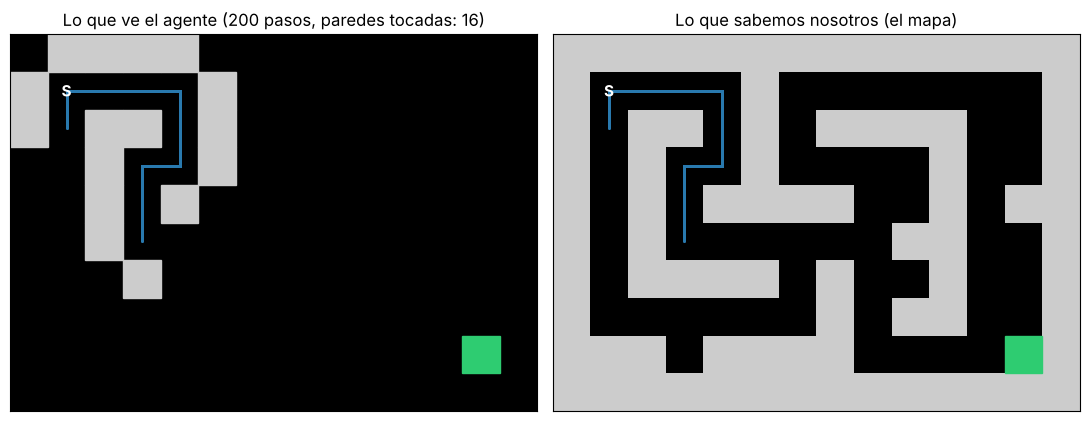

¿Llegó a la salida? False
Primeras 5 experiencias (s, r, s'): [(0, 0.0, 1), (1, 0.0, 1), (1, 0.0, 0), (0, 0.0, 0), (0, 0.0, 0)]


In [4]:
gamma = 0.99
env = CaveEnv(seed=1)
rng = np.random.default_rng(1)
traj = play_random_episode(env, rng, random_start=False)
path = [traj[0][0]] + [s2 for _, _, s2, _ in traj]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
plot_agent_view(env, path, axes[0], f"Lo que ve el agente ({len(traj)} pasos, paredes tocadas: {len(env.touched)})")
env.plot(ax=axes[1], path=path, title="Lo que sabemos nosotros (el mapa)")
plt.tight_layout(); plt.show()
print("¿Llegó a la salida?", traj[-1][3])
print("Primeras 5 experiencias (s, r, s'):", [(s, r, s2) for s, r, s2, _ in traj[:5]])

El agente no tiene $P$ ni $R$: solo tiene una lista de **experiencias** $(s, a, r, s')$. Todo lo de hoy se reduce a una idea: **reemplazar la suma sobre $P$ de la ecuación de Bellman por promedios de lo que efectivamente pasó**.

## Paso 2 — Monte Carlo: jugar hasta el final y promediar

Para evaluar la política aleatoria sin mapa, la forma más directa: jugar muchas partidas y, para cada casilla, **promediar el retorno que se obtuvo desde la primera vez que se pasó por ella** (*first-visit* MC):

$$V(s) \leftarrow V(s) + \frac{1}{N(s)}\big(G_t - V(s)\big)$$

donde $G_t$ es el retorno real desde esa visita hasta el final de la partida.

## Paso 3 — TD(0): aprender en cada paso

Monte Carlo tiene que esperar al final de la partida. TD actualiza **después de cada paso**, usando su propia estimación del lugar al que llegó (*bootstrapping*):

$$V(s) \leftarrow V(s) + \alpha\big(\underbrace{r + \gamma V(s')}_{\text{objetivo TD}} - V(s)\big)$$

Es la ecuación de Bellman de la clase 3, pero con **una sola muestra** $s'$ en lugar del promedio sobre $P$.

## Paso 4 — MC vs TD contra la respuesta correcta

Como nosotros sí tenemos el mapa, podemos calcular la $V$ verdadera de la política aleatoria (policy evaluation de la clase 3) y medir el error de cada método a medida que juega. En cada partida el agente **aparece en una casilla al azar** (si siempre arrancara en S, casi nunca vería la zona de la salida). MC y TD ven **exactamente las mismas partidas** (3 semillas, 1000 partidas, $\alpha = 0.1$ para TD).

Probamos dos situaciones:
- **Partidas largas** (hasta 1000 pasos): casi todas terminan en la salida.
- **Partidas cortadas a 200 pasos**, como en el juego: la mayoría se corta antes de llegar.

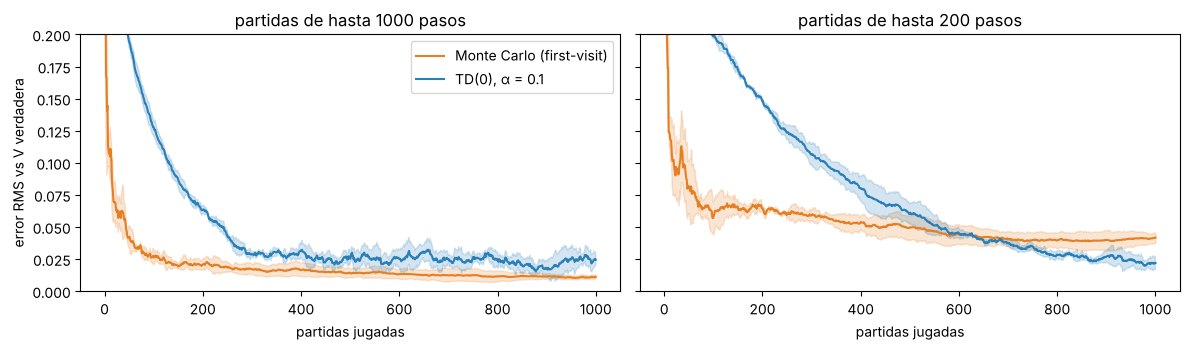

hasta 1000 pasos -> error final:  MC = 0.011   TD = 0.024
hasta  200 pasos -> error final:  MC = 0.042   TD = 0.022


In [5]:
results = {}
for max_steps in [1000, 200]:
    env_eval = CaveEnv(max_steps=max_steps)
    V_true = policy_evaluation(env_eval, np.full((env_eval.nS, 4), 0.25), gamma)
    results[max_steps] = compare_mc_td(env_eval, V_true, gamma, n_episodes=1000, alpha=0.1, seeds=range(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, max_steps in zip(axes, [1000, 200]):
    err_mc, err_td, _, _ = results[max_steps]
    ep = np.arange(1, err_mc.shape[1] + 1)
    for err, name, col in [(err_mc, "Monte Carlo (first-visit)", "#e67e22"), (err_td, "TD(0), α = 0.1", "#2980b9")]:
        m, sd = err.mean(0), err.std(0)
        ax.plot(ep, m, color=col, label=name)
        ax.fill_between(ep, m - sd, m + sd, color=col, alpha=0.2)
    ax.set_xlabel("partidas jugadas"); ax.set_title(f"partidas de hasta {max_steps} pasos")
    ax.set_ylim(0, 0.2)
axes[0].set_ylabel("error RMS vs V verdadera"); axes[0].legend()
plt.tight_layout(); plt.show()
for max_steps in [1000, 200]:
    err_mc, err_td, _, _ = results[max_steps]
    print(f"hasta {max_steps:4d} pasos -> error final:  MC = {err_mc[:, -1].mean():.3f}   TD = {err_td[:, -1].mean():.3f}")

Lo que muestran las curvas:

- **Monte Carlo** baja rápido desde el principio: cada partida trae retornos *reales* de todas las casillas que visitó.
- **TD** arranca más lento: el +1 de la salida tiene que **propagarse hacia atrás** casilla por casilla (como el frente de valor de la clase 3). Y con $\alpha$ fijo nunca llega a error cero: sigue "temblando" alrededor del valor correcto.
- Pero cuando las partidas se **cortan** (derecha), Monte Carlo se estanca: el retorno de una partida cortada no incluye lo que habría pasado después, así que subestima sistemáticamente (**sesgo**). TD no tiene ese problema: usa $V(s')$ como resumen de "lo que viene después", aunque la partida se haya cortado.

Este es el compromiso **sesgo vs varianza** (*bias–variance*): MC es insesgado si las partidas terminan, pero ruidoso; TD tiene algo de sesgo al principio (confía en sus propias estimaciones), pero aprende de cada paso y no necesita que la partida termine.

Veamos los mapas en el caso del juego (partidas de 200 pasos), con la misma escala de color:

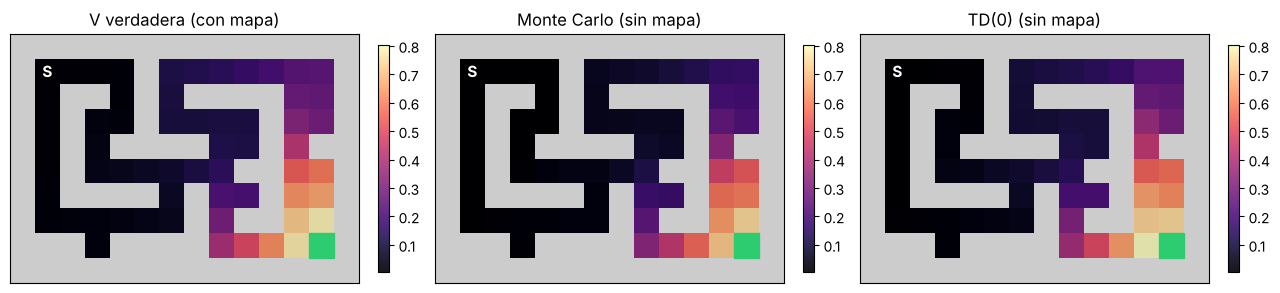

In [6]:
env_eval = CaveEnv(max_steps=200)
V_true = policy_evaluation(env_eval, np.full((env_eval.nS, 4), 0.25), gamma)
_, _, V_mc, V_td = results[200]
plot_row(env_eval, [V_true, V_mc, V_td],
         ["V verdadera (con mapa)", "Monte Carlo (sin mapa)", "TD(0) (sin mapa)"], size=4.3)

## Paso 5 — De evaluar a actuar: SARSA y Q-learning

Evaluar la política aleatoria está bien, pero queremos **salir de la cueva**. Sin mapa, $V(s)$ no alcanza para elegir: para saber qué flecha conviene necesitaríamos $P$. La solución es aprender directamente el valor de **cada acción** en cada casilla, $Q(s, a)$, y elegir la mejor.

Para no quedarnos siempre con lo primero que funcionó, usamos **$\varepsilon$-greedy**: con probabilidad $\varepsilon$ una acción al azar (explorar), si no la de mayor $Q$ (explotar).

Las dos recetas difieren en un solo término del objetivo TD:

$$\text{SARSA:}\quad Q(s,a) \leftarrow Q(s,a) + \alpha\big(r + \gamma\, Q(s', a') - Q(s,a)\big) \qquad a' = \text{la acción que efectivamente voy a hacer}$$

$$\text{Q-learning:}\quad Q(s,a) \leftarrow Q(s,a) + \alpha\big(r + \gamma \max_{a'} Q(s', a') - Q(s,a)\big) \qquad \text{la mejor acción posible}$$

SARSA aprende el valor de lo que *hace* (explorando incluida); Q-learning aprende el valor de la política óptima, aunque explore (*off-policy*).

### ¿Qué recompensa usar? Por qué `step_reward = -0.01`

Con la recompensa original (0 en cada paso, +1 en la salida) y $Q$ arrancando en 0, el agente no tiene ninguna pista hasta que encuentra la salida por casualidad (~5 % de las partidas de 200 pasos). Con un pequeño **costo por paso** (−0.01), cada acción que probó y no sirvió baja de 0, y las acciones **no probadas** (que siguen en 0) pasan a parecer mejores: el agente prefiere lo nuevo. Comparemos con Q-learning, 5 semillas:

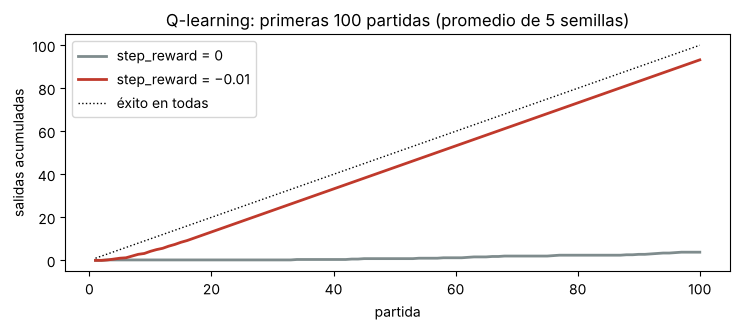

step_reward = 0    : primera salida en las partidas [43, 62, 34, 58, 3]
step_reward = -0.01: primera salida en las partidas [5, 4, 3, 7, 4]


In [7]:
seeds = range(5)
runs_0 = [learn(CaveEnv(step_reward=0.0), "qlearning", n_episodes=100, seed=k) for k in seeds]
runs_c = [learn(CaveEnv(step_reward=-0.01), "qlearning", n_episodes=100, seed=k) for k in seeds]

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for runs, name, col in [(runs_0, "step_reward = 0", "#7f8c8d"), (runs_c, "step_reward = −0.01", "#c0392b")]:
    cum = np.mean([np.cumsum(r["success"]) for r in runs], axis=0)
    ax.plot(np.arange(1, 101), cum, color=col, lw=2, label=name)
ax.plot([1, 100], [1, 100], "k:", lw=1, label="éxito en todas")
ax.set_xlabel("partida"); ax.set_ylabel("salidas acumuladas")
ax.set_title("Q-learning: primeras 100 partidas (promedio de 5 semillas)")
ax.legend(); plt.tight_layout(); plt.show()
for runs, name in [(runs_0, "0    "), (runs_c, "-0.01")]:
    first = [int(np.argmax(r["success"])) + 1 for r in runs]
    print(f"step_reward = {name}: primera salida en las partidas {first}")

Con costo por paso el agente encuentra la salida en las primeras partidas; sin costo, tarda decenas. Además, la política óptima es la misma en los dos casos (lo vimos en la clase 3 con $\gamma = 0.99$), así que el costo **no cambia el objetivo, solo acelera el aprendizaje**. Desde acá usamos `step_reward = -0.01`. (Este "optimismo ante lo desconocido" es el tema de la clase 5.)

## Paso 6 — Curvas de aprendizaje: SARSA vs Q-learning

500 partidas desde S, $\alpha = 0.5$, $\varepsilon = 0.1$, 5 semillas. Miramos pasos por partida (menos es mejor; el camino más corto tiene 20) y tasa de éxito (media móvil de 20 partidas).

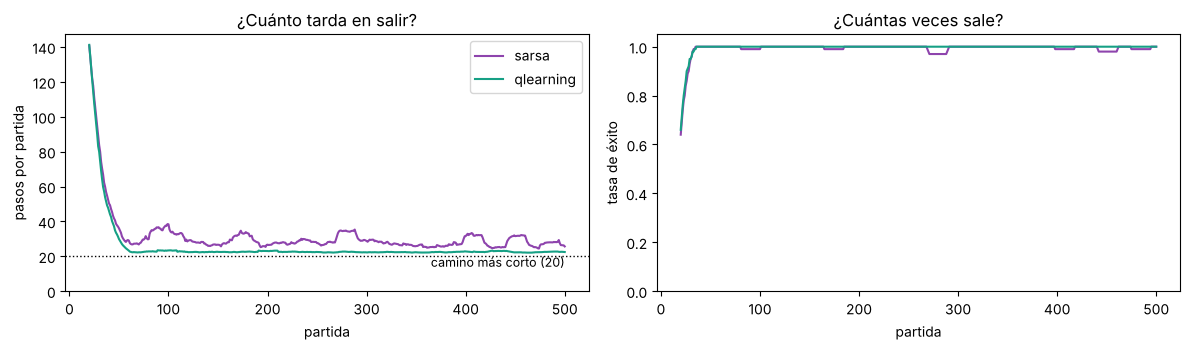

sarsa      últimas 100 partidas: éxito = 0.99, pasos = 27.6
qlearning  últimas 100 partidas: éxito = 1.00, pasos = 22.5


In [8]:
env_c = CaveEnv(step_reward=-0.01)
runs = {m: [learn(env_c, m, n_episodes=500, alpha=0.5, epsilon=0.1, seed=k) for k in seeds]
        for m in ["sarsa", "qlearning"]}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for m, col in [("sarsa", "#8e44ad"), ("qlearning", "#16a085")]:
    st = np.array([smooth(r["steps"]) for r in runs[m]])
    sc = np.array([smooth(r["success"]) for r in runs[m]])
    x = np.arange(st.shape[1]) + 20
    axes[0].plot(x, st.mean(0), color=col, label=m)
    axes[1].plot(x, sc.mean(0), color=col, label=m)
axes[0].axhline(20, color="k", ls=":", lw=1); axes[0].text(500, 14, "camino más corto (20)", ha="right", fontsize=9)
axes[0].set_ylim(0, None); axes[0].set_ylabel("pasos por partida"); axes[0].set_xlabel("partida")
axes[1].set_ylabel("tasa de éxito"); axes[1].set_xlabel("partida"); axes[1].set_ylim(0, 1.05)
axes[0].set_title("¿Cuánto tarda en salir?"); axes[1].set_title("¿Cuántas veces sale?")
axes[0].legend(); plt.tight_layout(); plt.show()
for m in runs:
    print(f"{m:10s} últimas 100 partidas: éxito = {np.mean([r['success'][-100:].mean() for r in runs[m]]):.2f}, "
          f"pasos = {np.mean([r['steps'][-100:].mean() for r in runs[m]]):.1f}")

Los dos aprenden a salir en unas pocas decenas de partidas; SARSA queda más irregular y con partidas algo más largas. Los pasos no bajan exactamente a 20 porque el agente **sigue explorando** el 10 % de las veces ($\varepsilon = 0.1$): de vez en cuando se desvía a propósito.

## Paso 7 — Lo aprendido vs lo óptimo

De la tabla $Q$ sacamos lo mismo que en la clase 3:
- un valor por casilla: $V(s) = \max_a Q(s, a)$,
- una política: $\pi(s) = \arg\max_a Q(s, a)$ (sin explorar).

Comparemos con value iteration (con mapa) sobre la misma cueva con costo por paso.

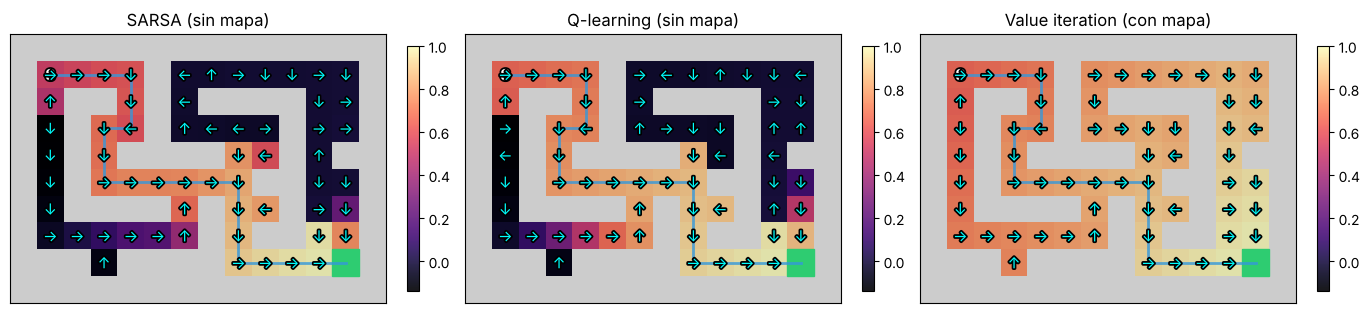

sarsa      V(S) = 0.522   (V*(S) = 0.652)   camino greedy: 20 pasos   flechas óptimas: 76 %
qlearning  V(S) = 0.652   (V*(S) = 0.652)   camino greedy: 20 pasos   flechas óptimas: 78 %


In [9]:
V_star, pi_star, Q_star = value_iteration(env_c, gamma)
res = {m: runs[m][0] for m in runs}            # semilla 0 de cada método
V_learn = {m: res[m]["Q"].max(axis=1) for m in res}
pi_learn = {m: res[m]["Q"].argmax(axis=1) for m in res}

plot_row(env_c, [V_learn["sarsa"], V_learn["qlearning"], V_star],
         ["SARSA (sin mapa)", "Q-learning (sin mapa)", "Value iteration (con mapa)"],
         policies=[pi_learn["sarsa"], pi_learn["qlearning"], pi_star],
         paths=[run_policy(env_c, pi_learn["sarsa"]), run_policy(env_c, pi_learn["qlearning"]),
                run_policy(env_c, pi_star)], size=4.6)

for m in res:
    p = run_policy(env_c, pi_learn[m])
    print(f"{m:10s} V(S) = {V_learn[m][env_c.start]:.3f}   (V*(S) = {V_star[env_c.start]:.3f})   "
          f"camino greedy: {len(p) - 1} pasos   flechas óptimas: {100 * frac_optimal(env_c, pi_learn[m], Q_star):.0f} %")

Lo que se ve:

- La **trayectoria greedy** desde S es el camino más corto en los dos casos: el agente aprendió a salir sin ver nunca el mapa.
- **Q-learning** estima $V(S)$ muy cerca de $V^*(S)$: aprende el valor de la política óptima aunque explore. **SARSA** da un valor algo menor: aprende el valor de la política que *realmente* juega, con sus desvíos de exploración incluidos.
- Lejos del camino el aprendizaje quedó a medias: arriba a la derecha el valor aprendido es casi 0 (aunque $V^*$ es alto) y hay flechas raras. ¿Por qué? Miremos dónde estuvo el agente.

## Paso 8 — El mapa de visitas

¿Cuántas veces pisó cada casilla? Usamos otro mapa de color (escala log) para no confundirlo con $V$. A la izquierda, las primeras 50 partidas (cuando todavía no sabía salir); a la derecha, las últimas 250 (cuando ya sabía).

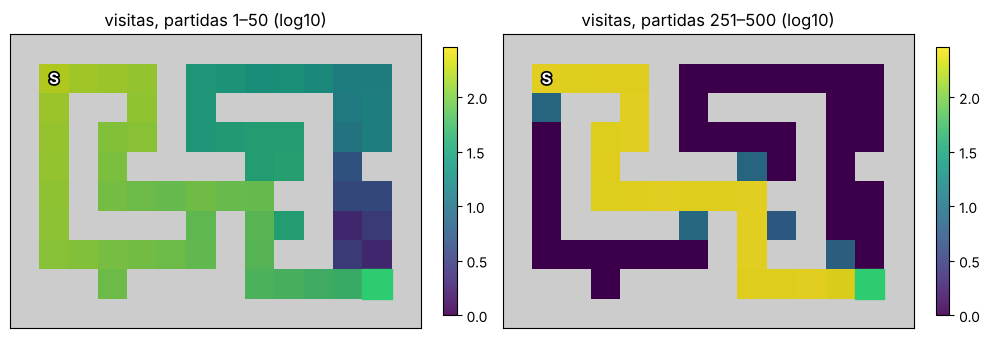

In [10]:
vis = res["qlearning"]["visits"]
early, late = vis[:50].sum(0), vis[250:].sum(0)
plot_row(env_c, [np.log10(1 + early), np.log10(1 + late)],
         ["visitas, partidas 1–50 (log10)", "visitas, partidas 251–500 (log10)"],
         shared=True, cmap="viridis", size=5)

Al principio el agente recorre toda la cueva; una vez que encontró el camino, casi no sale de él (el 10 % de exploración solo lo corre una casilla y vuelve). ¿Qué consecuencia tiene eso sobre lo que aprendió? Comparemos, casilla por casilla, el error de su $V$ contra $V^*$ con cuántas veces la visitó en la segunda mitad:

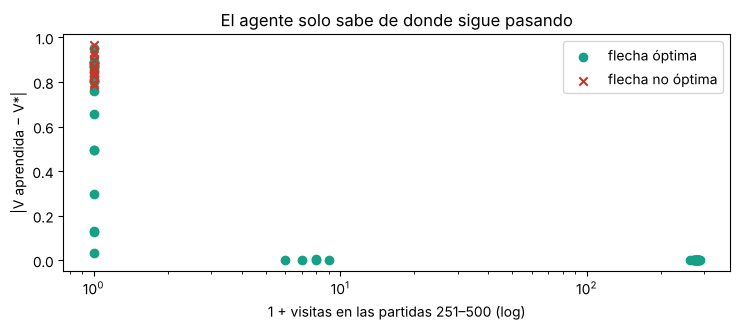

In [11]:
opt = np.isclose(Q_star, Q_star.max(1, keepdims=True), atol=1e-6)
ok = np.array([opt[s, pi_learn["qlearning"][s]] for s in range(env_c.nS)])
err = np.abs(V_learn["qlearning"] - V_star)
ng = np.arange(env_c.nS) != env_c.goal
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.scatter(1 + late[ng & ok], err[ng & ok], color="#16a085", label="flecha óptima")
ax.scatter(1 + late[ng & ~ok], err[ng & ~ok], color="#c0392b", marker="x", label="flecha no óptima")
ax.set_xscale("log"); ax.set_xlabel("1 + visitas en las partidas 251–500 (log)")
ax.set_ylabel("|V aprendida − V*|"); ax.set_title("El agente solo sabe de donde sigue pasando")
ax.legend(); plt.tight_layout(); plt.show()

Dos grupos bien separados: las casillas por las que **siguió pasando** tienen $V$ prácticamente exacta y flecha óptima; las que **dejó de visitar** quedaron congeladas con lo que sabía al principio, cuando todavía no había encontrado la salida (error grande, flechas a veces equivocadas). Al agente no le importa, porque nunca las usa.

Esto funciona en esta cueva chica. ¿Y si la cueva fuera 100 veces más grande, o la salida estuviera escondida detrás de un pasillo largo? Una exploración al azar del 10 % no alcanzaría para encontrarla nunca: es el problema de la **recompensa escasa** (*sparse reward*), tema de la clase 5.

## ✍️ Ejercicio 1 — Cuánto explorar: $\varepsilon$

Cambiá `eps_ej` (probá 0.01, 0.3, 0.5). Mirá la tasa de éxito, los pasos por partida y el mapa de visitas: ¿qué pasa con poca y con mucha exploración?

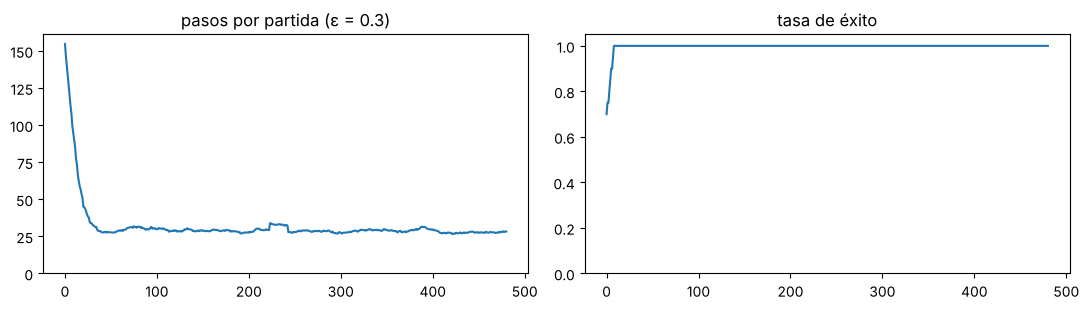

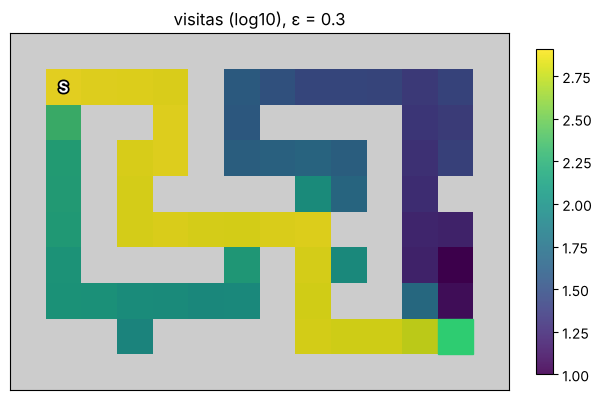

In [12]:
eps_ej = 0.3   # TODO: probá 0.01, 0.3, 0.5

r_ej = learn(env_c, "qlearning", n_episodes=500, alpha=0.5, epsilon=eps_ej, seed=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(smooth(r_ej["steps"])); axes[0].set_ylim(0, None); axes[0].set_title(f"pasos por partida (ε = {eps_ej})")
axes[1].plot(smooth(r_ej["success"])); axes[1].set_ylim(0, 1.05); axes[1].set_title("tasa de éxito")
plt.tight_layout(); plt.show()
plot_cave(env_c, values=np.log10(1 + r_ej["visits"].sum(0)), cmap="viridis",
          title=f"visitas (log10), ε = {eps_ej}")
plt.show()

## ✍️ Ejercicio 2 — Cuánto aprender de cada paso: $\alpha$

Cambiá `alpha_ej` (probá 0.05, 0.9). ¿Aprende más rápido o más lento? ¿Qué tan cerca queda $V(S)$ de $V^*(S)$?

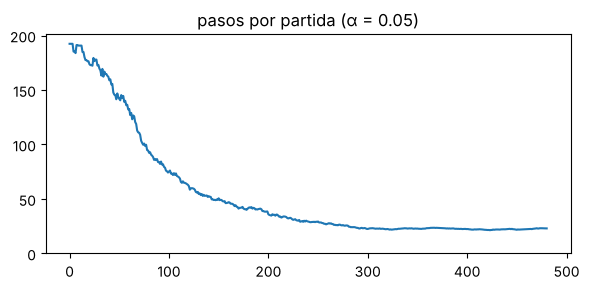

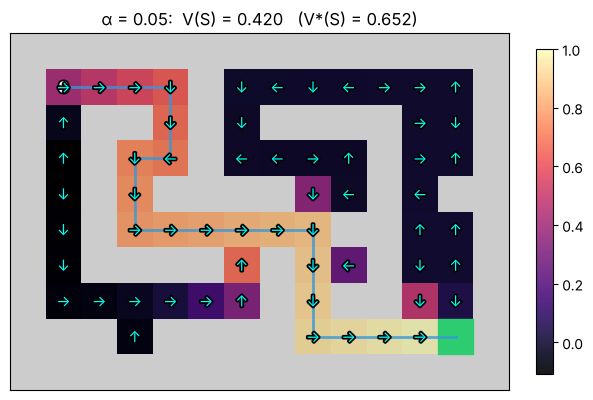

In [13]:
alpha_ej = 0.05   # TODO: probá 0.05, 0.9

r_ej = learn(env_c, "qlearning", n_episodes=500, alpha=alpha_ej, epsilon=0.1, seed=0)
V_ej, pi_ej = r_ej["Q"].max(1), r_ej["Q"].argmax(1)
fig, ax = plt.subplots(figsize=(6, 3)); ax.plot(smooth(r_ej["steps"])); ax.set_ylim(0, None)
ax.set_title(f"pasos por partida (α = {alpha_ej})"); plt.tight_layout(); plt.show()
plot_cave(env_c, values=V_ej, policy=pi_ej, path=run_policy(env_c, pi_ej),
          title=f"α = {alpha_ej}:  V(S) = {V_ej[env_c.start]:.3f}   (V*(S) = {V_star[env_c.start]:.3f})")
plt.show()

## Preguntas para pensar

1. Monte Carlo necesita que la partida **termine** para actualizar. ¿Qué pasa en un problema que no termina nunca (por ejemplo, un tutor que acompaña a un alumno todo el año)? ¿Cuál de los dos métodos usarías?
2. En el Paso 8 el agente dejó valores y flechas equivocados lejos del camino. ¿Es un problema? ¿En qué situación sí lo sería (pensá en el piso resbaloso de la clase 3)?
3. La tabla $Q$ tiene 60 × 4 = 240 números. ¿Cuántos tendría si el estado fuera una imagen de 84 × 84 píxeles? ¿Qué podríamos usar en lugar de una tabla?

## Próxima clase

¿Qué pasa cuando la salida está tan lejos que el azar nunca la encuentra? Vamos a premiar al agente por ir **adonde nunca fue** (curiosidad por conteo, usando justamente este mapa de visitas) y a ver Go-Explore. Un puente: $\varepsilon$ cumple el mismo papel que la **temperatura** al muestrear un modelo de lenguaje: más alta, respuestas más variadas y arriesgadas; más baja, siempre lo más probable.